
1. FE GLOBAL
Beta: -0.8831
P-value: 1.0440e-17

2. FE CON INTERACCIONES
Bucket_0: beta=-1.3190, p-value=8.0513e-18
Bucket_1: beta=-1.2433, p-value=3.5876e-14
Bucket_2: beta=-1.0499, p-value=2.2340e-15
Bucket_3: beta=-0.5665, p-value=9.7025e-05
Bucket_4: beta=-0.3280, p-value=4.4986e-03

3. RE / MODELO MIXTO
            Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  conversion_Y
No. Observations:  120      Method:              REML        
No. Groups:        5        Scale:               0.0000      
Min. group size:   24       Log-Likelihood:      330.7944    
Max. group size:   24       Converged:           Yes         
Mean group size:   24.0                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           0.495    0.035 14.105 0.000  0.426  0.563
C(mes)[T.1]         

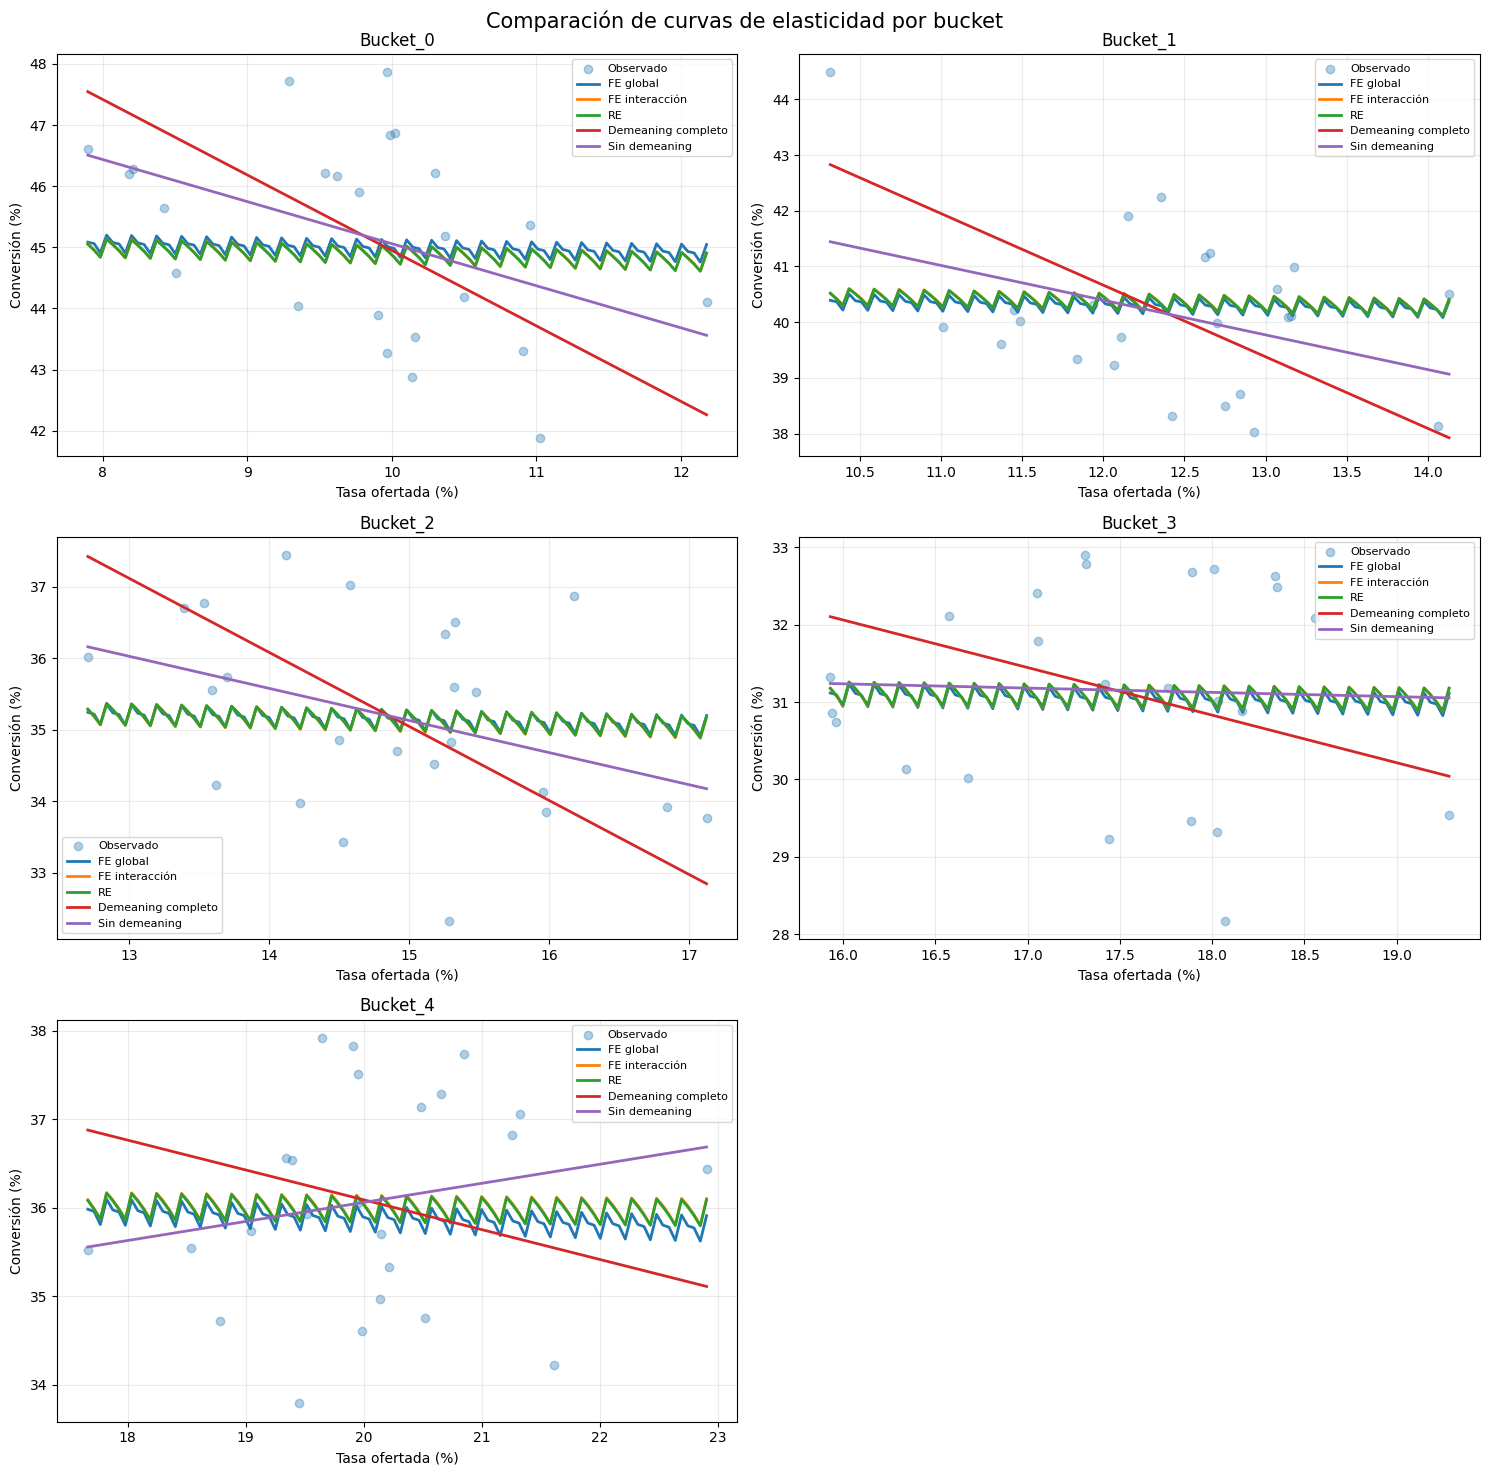

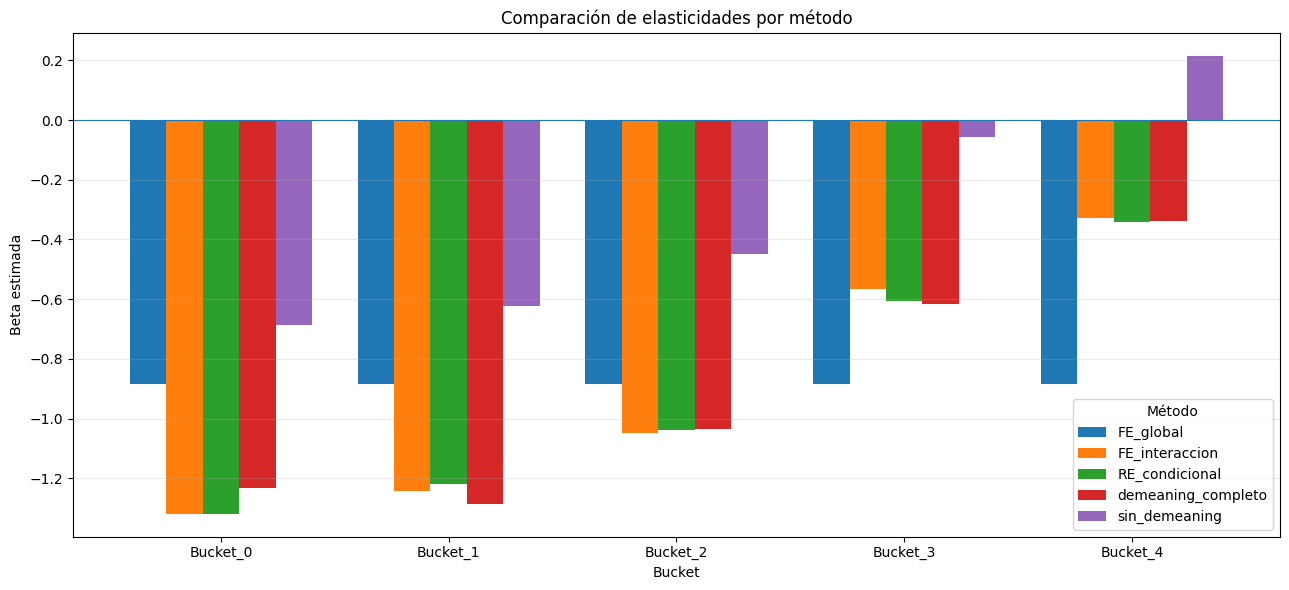

In [1]:

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# ============================================================
# 1. GENERACIÓN DE DATA SINTÉTICA
# ============================================================

np.random.seed(42)

n_buckets = 5
n_periodos = 24

alpha_i = np.array([0.10, 0.05, 0.00, -0.05, -0.10])
gamma_t = 0.02 * np.sin(np.linspace(0, 4 * np.pi, n_periodos))

beta_verdaderos = {
    0: -1.5,
    1: -1.2,
    2: -1.0,
    3: -0.8,
    4: -0.2
}

records = []

for i in range(n_buckets):
    for t in range(n_periodos):

        tasa_X = (
            0.15
            - 0.5 * alpha_i[i]
            + 0.3 * gamma_t[t]
            + np.random.normal(0, 0.01)
        )

        conversion_Y = (
            0.50
            + alpha_i[i]
            + gamma_t[t]
            + beta_verdaderos[i] * tasa_X
            + np.random.normal(0, 0.005)
        )

        records.append({
            "bucket": f"Bucket_{i}",
            "mes": t,
            "conversion_Y": conversion_Y,
            "tasa_X": tasa_X
        })

df = pd.DataFrame(records)
df["bucket"] = df["bucket"].astype(str)

buckets = sorted(df["bucket"].unique())
meses = sorted(df["mes"].unique())

# ============================================================
# 2. FE GLOBAL: UNA BETA COMÚN
# ============================================================

fe_global = smf.ols(
    "conversion_Y ~ tasa_X + C(bucket) + C(mes)",
    data=df
).fit()

beta_global = fe_global.params["tasa_X"]

print("\n1. FE GLOBAL")
print(f"Beta: {beta_global:.4f}")
print(f"P-value: {fe_global.pvalues['tasa_X']:.4e}")

# ============================================================
# 3. FE CON INTERACCIONES: UNA BETA POR BUCKET
# ============================================================

for bucket in buckets:
    df[f"tasa_{bucket}"] = (
        df["tasa_X"] * (df["bucket"] == bucket).astype(int)
    )

formula_inter = (
    "conversion_Y ~ C(bucket) + C(mes) + "
    + " + ".join(f"tasa_{b}" for b in buckets)
)

fe_inter = smf.ols(formula_inter, data=df).fit()

print("\n2. FE CON INTERACCIONES")

for bucket in buckets:
    nombre = f"tasa_{bucket}"
    print(
        f"{bucket}: beta={fe_inter.params[nombre]:.4f}, "
        f"p-value={fe_inter.pvalues[nombre]:.4e}"
    )

# ============================================================
# 4. RE: MODELO MIXTO CON PENDIENTES ALEATORIAS
# ============================================================

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")

    re_model = smf.mixedlm(
        "conversion_Y ~ tasa_X + C(mes)",
        data=df,
        groups=df["bucket"],
        re_formula="~tasa_X"
    ).fit(
        reml=True,
        method="lbfgs",
        maxiter=2000,
        disp=False
    )

print("\n3. RE / MODELO MIXTO")
print(re_model.summary())

if not re_model.converged:
    print("ADVERTENCIA: el modelo RE no convergió.")

# ============================================================
# 5. TWO-WAY DEMEANING MANUAL
#    ELIMINAMOS EFECTOS DE BUCKET Y MES
# ============================================================

df_dm = df.copy()

for var in ["tasa_X", "conversion_Y"]:
    df_dm[f"{var}_dm"] = (
        df_dm[var]
        - df_dm.groupby("bucket")[var].transform("mean")
        - df_dm.groupby("mes")[var].transform("mean")
        + df_dm[var].mean()
    )

resultados_dm = {}

for bucket in buckets:
    sub = df_dm[df_dm["bucket"] == bucket]

    modelo = smf.ols(
        "conversion_Y_dm ~ 0 + tasa_X_dm",
        data=sub
    ).fit()

    resultados_dm[bucket] = {
        "beta": modelo.params["tasa_X_dm"],
        "p_value": modelo.pvalues["tasa_X_dm"]
    }

print("\n4. REGRESIONES CON TWO-WAY DEMEANING")

for bucket in buckets:
    r = resultados_dm[bucket]
    print(
        f"{bucket}: beta={r['beta']:.4f}, "
        f"p-value={r['p_value']:.4e}"
    )

# ============================================================
# 6. REGRESIONES INDEPENDIENTES SIN DEMEANING
# ============================================================

modelos_ind = {}
resultados_ind = {}

print("\n5. REGRESIONES INDEPENDIENTES SIN DEMEANING")

for bucket in buckets:
    sub = df[df["bucket"] == bucket]

    modelo = smf.ols(
        "conversion_Y ~ tasa_X",
        data=sub
    ).fit()

    modelos_ind[bucket] = modelo

    resultados_ind[bucket] = {
        "beta": modelo.params["tasa_X"],
        "p_value": modelo.pvalues["tasa_X"],
        "intercepto": modelo.params["Intercept"]
    }

    print(
        f"{bucket}: beta={modelo.params['tasa_X']:.4f}, "
        f"p-value={modelo.pvalues['tasa_X']:.4e}"
    )

# ============================================================
# 7. TABLA COMPARATIVA DE BETAS
# ============================================================

filas = []

for bucket in buckets:
    i = int(bucket.split("_")[1])

    efectos_re = re_model.random_effects[bucket]

    filas.append({
        "bucket": bucket,
        "beta_real": beta_verdaderos[i],
        "FE_global": beta_global,
        "FE_interaccion": fe_inter.params[f"tasa_{bucket}"],
        "RE_condicional": (
            re_model.fe_params["tasa_X"] + efectos_re.iloc[1]
        ),
        "demeaning_completo": resultados_dm[bucket]["beta"],
        "sin_demeaning": resultados_ind[bucket]["beta"]
    })

tabla_betas = pd.DataFrame(filas)

print("\n6. COMPARACIÓN DE BETAS")
print(tabla_betas.to_string(index=False, float_format="%.4f"))

# ============================================================
# 8. CONSTRUCCIÓN DE CURVAS COMPARABLES
# ============================================================

curvas = []

def agregar_curva(modelo, bucket, tasas, conversiones):
    curvas.append(pd.DataFrame({
        "modelo": modelo,
        "bucket": bucket,
        "tasa_X": np.asarray(tasas),
        "conversion_predicha": np.asarray(conversiones)
    }))

for bucket in buckets:

    sub = df[df["bucket"] == bucket]

    tasa_grid = np.linspace(
        sub["tasa_X"].min(),
        sub["tasa_X"].max(),
        100
    )

    # Base con cada tasa y cada mes
    pred = pd.DataFrame([
        {"bucket": bucket, "mes": mes, "tasa_X": tasa}
        for tasa in tasa_grid
        for mes in meses
    ])

    for b in buckets:
        pred[f"tasa_{b}"] = (
            pred["tasa_X"] * (pred["bucket"] == b).astype(int)
        )

    # FE global: promediamos sobre los meses
    pred["y_fe_global"] = fe_global.predict(pred)

    curva_global = (
        pred.assign(tasa_grid=np.tile(tasa_grid, len(meses)))
        .groupby("tasa_grid")["y_fe_global"]
        .mean()
    )

    agregar_curva(
        "FE global", bucket,
        curva_global.index, curva_global.values
    )

    # FE con interacción
    pred["y_fe_inter"] = fe_inter.predict(pred)

    curva_inter = (
        pred.assign(tasa_grid=np.tile(tasa_grid, len(meses)))
        .groupby("tasa_grid")["y_fe_inter"]
        .mean()
    )

    agregar_curva(
        "FE interacción", bucket,
        curva_inter.index, curva_inter.values
    )

    # RE: predicción fija + efectos aleatorios del bucket
    pred["y_re_fijo"] = re_model.predict(pred)

    efectos_re = re_model.random_effects[bucket]

    pred["y_re"] = (
        pred["y_re_fijo"]
        + efectos_re.iloc[0]
        + efectos_re.iloc[1] * pred["tasa_X"]
    )

    curva_re = (
        pred.assign(tasa_grid=np.tile(tasa_grid, len(meses)))
        .groupby("tasa_grid")["y_re"]
        .mean()
    )

    agregar_curva(
        "RE", bucket,
        curva_re.index, curva_re.values
    )

    # Two-way demeaning: pendiente centrada en medias originales
    beta_dm = resultados_dm[bucket]["beta"]

    y_dm = (
        sub["conversion_Y"].mean()
        + beta_dm * (tasa_grid - sub["tasa_X"].mean())
    )

    agregar_curva(
        "Demeaning completo", bucket, tasa_grid, y_dm
    )

    # OLS independiente sin demeaning
    modelo_ind = modelos_ind[bucket]

    y_ind = (
        modelo_ind.params["Intercept"]
        + modelo_ind.params["tasa_X"] * tasa_grid
    )

    agregar_curva(
        "Sin demeaning", bucket, tasa_grid, y_ind
    )

curvas = pd.concat(curvas, ignore_index=True)

# ============================================================
# 9. GRÁFICAS COMPARATIVAS POR BUCKET
# ============================================================

modelos_orden = [
    "FE global",
    "FE interacción",
    "RE",
    "Demeaning completo",
    "Sin demeaning"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 15))
axes = axes.flatten()

for idx, bucket in enumerate(buckets):

    ax = axes[idx]

    datos_bucket = df[df["bucket"] == bucket]
    curvas_bucket = curvas[curvas["bucket"] == bucket]

    ax.scatter(
        datos_bucket["tasa_X"] * 100,
        datos_bucket["conversion_Y"] * 100,
        alpha=0.35,
        label="Observado"
    )

    for modelo in modelos_orden:
        c = curvas_bucket[curvas_bucket["modelo"] == modelo]

        ax.plot(
            c["tasa_X"] * 100,
            c["conversion_predicha"] * 100,
            linewidth=2,
            label=modelo
        )

    ax.set_title(bucket)
    ax.set_xlabel("Tasa ofertada (%)")
    ax.set_ylabel("Conversión (%)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.delaxes(axes[-1])

fig.suptitle(
    "Comparación de curvas de elasticidad por bucket",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ============================================================
# 10. GRÁFICA COMPARATIVA DE BETAS
# ============================================================

columnas_betas = [
    "FE_global",
    "FE_interaccion",
    "RE_condicional",
    "demeaning_completo",
    "sin_demeaning"
]

ax = tabla_betas.set_index("bucket")[columnas_betas].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

ax.set_title("Comparación de elasticidades por método")
ax.set_xlabel("Bucket")
ax.set_ylabel("Beta estimada")
ax.axhline(0, linewidth=0.8)
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.legend(title="Método")
plt.tight_layout()
plt.show()


In [2]:
import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS

# ============================================================
# 1. PREPARAR PANEL
# ============================================================

df_panel = df.copy()

df_panel['bucket'] = df_panel['bucket'].astype(str)

# Índice del panel
df_indexed = (
    df_panel
    .set_index(['bucket', 'mes'])
    .sort_index()
)

buckets = sorted(df_panel['bucket'].unique())

# ============================================================
# 2. FE GLOBAL: UNA BETA COMÚN
# ============================================================

mod_global = PanelOLS(
    dependent=df_indexed['conversion_Y'],
    exog=df_indexed[['tasa_X']],
    entity_effects=True,
    time_effects=True,
    drop_absorbed=True
)

fe_global = mod_global.fit(cov_type='unadjusted')

print('\n1. FE GLOBAL')
print(f'Beta: {fe_global.params["tasa_X"]:.4f}')
print(f'P-value: {fe_global.pvalues["tasa_X"]:.4e}')

# ============================================================
# 3. FE CON INTERACCIONES: UNA BETA POR BUCKET
# ============================================================

nombres_interaccion = {}

for i, bucket in enumerate(buckets):
    nombre = f'tasa_inter_{i}'

    df_indexed[nombre] = (
        df_indexed['tasa_X']
        * (
            df_indexed.index.get_level_values('bucket') == bucket
        ).astype(int)
    )

    nombres_interaccion[bucket] = nombre

exog_inter = df_indexed[
    list(nombres_interaccion.values())
]

mod_inter = PanelOLS(
    dependent=df_indexed['conversion_Y'],
    exog=exog_inter,
    entity_effects=True,
    time_effects=True,
    drop_absorbed=True
)

fe_inter = mod_inter.fit(cov_type='unadjusted')

print('\n2. FE CON INTERACCIONES')

for bucket, nombre in nombres_interaccion.items():
    beta = fe_inter.params.get(nombre, np.nan)
    pvalue = fe_inter.pvalues.get(nombre, np.nan)

    print(
        f'{bucket}: beta={beta:.4f}, '
        f'p-value={pvalue:.4e}'
    )


1. FE GLOBAL
Beta: -0.8831
P-value: 0.0000e+00

2. FE CON INTERACCIONES
Bucket_0: beta=-1.3190, p-value=0.0000e+00
Bucket_1: beta=-1.2433, p-value=3.5749e-14
Bucket_2: beta=-1.0499, p-value=2.2204e-15
Bucket_3: beta=-0.5665, p-value=9.7025e-05
Bucket_4: beta=-0.3280, p-value=4.4986e-03
